# MDS Maps
This notebook creates and analyzes MDS maps. 

The code for creating and analyzing the maps was generated by Claude Code.
## 1. Forming the full dissimilarity matrix
We have all pairwise distances to create the full dissimilarity matrix; this however still has to be filled from the given distances using the symmetry properties.

First, we create a list of all copulas, including all their transformations:

In [ ]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # project root, so the distance_calculation_campaign imports resolve

from distance_calculation_campaign import unique_pairs
import pandas as pd
import json
from sklearn.manifold import MDS

# Make list of all 100 copulas
all_copulas = []
for copula in unique_pairs.unique_shapes_category_0:
    all_copulas.append(copula)
    all_copulas.append(copula + "!T!M0")
    all_copulas.append(copula + "!M0")
    all_copulas.append(copula + "!T")
    all_copulas.append(copula + "!T!M01")
    all_copulas.append(copula + "!T!M1")
    all_copulas.append(copula + "!M1")
    all_copulas.append(copula + "!M01")

for copula in unique_pairs.unique_shapes_category_1:
    all_copulas.append(copula)
    all_copulas.append(copula + "!M0")
    all_copulas.append(copula + "!M1")
    all_copulas.append(copula + "!M01")

for copula in unique_pairs.unique_shapes_category_2:
    all_copulas.append(copula)
    all_copulas.append(copula + "!M0")

for copula in unique_pairs.unique_shapes_category_3:
    all_copulas.append(copula)
    all_copulas.append(copula + "!M1")
    all_copulas.append(copula + "!T")
    all_copulas.append(copula + "!T!M0")

for copula in unique_pairs.unique_shapes_category_4:
    all_copulas.append(copula)



In [2]:
# Import data from run
with open("../distance_calculation_campaign/unique_pairs.json") as f:
    row_list = json.load(f)

for row in row_list:
    row['copula0'], row['copula1'] = row['pair'].split("/")

row_dict = {row["pair"]: row for row in row_list}



We then define two dictionaries of transformations. 

`transformation_1` takes the transformations of $c_0$ and $c_1$ and maps to it the result applying the transformations to $c_0$ in reverse after the transformations to $c_1$. for example, given two transformed densities $c_0^{T, M_0}$ and $c_1^{T, M_{01}}$, the distance between them is equal to the distance between $c_0$ and $c_1^{T, M_{01}, M_0, T}$, which simplified is the distance between $c_0$ and $c_1^{M_0}$. Therefore, `("!T!M0",  "!T!M01")` is matched with the value `"!M0"` in the dictionary.

`transformation_2` uses symmetry group-specific properties and maps a $3$-tuple of the transformation resulting from `transformation_1` and the symmetry groups of $c_0$ and $c_1$ to a new transformation. (The symmetry groups are encoded as integers using Group A = 0, Group B = 1, ...) This new transformation is the one that can be found in the list of distances actually calculated in `unique_pairs.json`. For example, we take the distance between a base density $c_0$ from Symmetry Group B and a transformed density $c_1^{T, M_1}$ with $c_1$ in Symmetry Group D. Group B is invariant under `T` and Group D is invariant under `M_0`; therefore, $\mathcal{CW}(c_0, c_1^{T, M_1}) = \mathcal{CW}(c_0^T, c_1^{M_0, T, M_1})$. Using traits not specific to the symmetry groups, $\mathcal{CW}(c_0^T, c_1^{M_0, T, M_1}) = \mathcal{CW}(c_0^T, c_1^{T, M_1, M_1}) = \mathcal{CW}(c_0^T, c_1^{T}) = \mathcal{CW}(c_0, c_1)$. Thus, the tuple `("!T!M1",   1, 3)` is matched to `""`, the transformation applied to $c_1$ in the list of calculated distances.


In [3]:
transformation_1 = {
    ("",       "")      : "",
    ("",       "!T!M0") : "!T!M0",
    ("",       "!M0")   : "!M0",
    ("",       "!T")    : "!T",
    ("",       "!T!M01"): "!T!M01",
    ("",       "!T!M1") : "!T!M1",
    ("",       "!M1")   : "!M1",
    ("",       "!M01")  : "!M01",
    ("!T!M0",  "")      : "!T!M1",
    ("!T!M0",  "!T!M0") : "",
    ("!T!M0",  "!M0")   : "!T",
    ("!T!M0",  "!T")    : "!M1",
    ("!T!M0",  "!T!M01"): "!M0",
    ("!T!M0",  "!T!M1") : "!M01",
    ("!T!M0",  "!M1")   : "!T!M01",
    ("!T!M0",  "!M01")  : "!T!M0",
    ("!M0",    "")      : "!M0",
    ("!M0",    "!T!M0") : "!T",
    ("!M0",    "!M0")   : "",
    ("!M0",    "!T")    : "!T!M0",
    ("!M0",    "!T!M01"): "!T!M1",
    ("!M0",    "!T!M1") : "!T!M01",
    ("!M0",    "!M1")   : "!M01",
    ("!M0",    "!M01")  : "!M1",
    ("!T",     "")      : "!T",
    ("!T",     "!T!M0") : "!M1",
    ("!T",     "!M0")   : "!T!M1",
    ("!T",     "!T")    : "",
    ("!T",     "!T!M01"): "!M01",
    ("!T",     "!T!M1") : "!M0",
    ("!T",     "!M1")   : "!T!M0",
    ("!T",     "!M01")  : "!T!M01",
    ("!T!M01", "")      : "!T!M01",
    ("!T!M01", "!T!M0") : "!M0",
    ("!T!M01", "!M0")   : "!T!M0",
    ("!T!M01", "!T")    : "!M01",
    ("!T!M01", "!T!M01"): "",
    ("!T!M01", "!T!M1") : "!M1",
    ("!T!M01", "!M1")   : "!T!M1",
    ("!T!M01", "!M01")  : "!T",
    ("!T!M1",  "")      : "!T!M0",
    ("!T!M1",  "!T!M0") : "!M01",
    ("!T!M1",  "!M0")   : "!T!M01",
    ("!T!M1",  "!T")    : "!M0",
    ("!T!M1",  "!T!M01"): "!M1",
    ("!T!M1",  "!T!M1") : "",
    ("!T!M1",  "!M1")   : "!T",
    ("!T!M1",  "!M01")  : "!T!M1",
    ("!M1",    "")      : "!M1",
    ("!M1",    "!T!M0") : "!T!M01",
    ("!M1",    "!M0")   : "!M01",
    ("!M1",    "!T")    : "!T!M1",
    ("!M1",    "!T!M01"): "!T!M0",
    ("!M1",    "!T!M1") : "!T",
    ("!M1",    "!M1")   : "",
    ("!M1",    "!M01")  : "!M0",
    ("!M01",   "")      : "!M01",
    ("!M01",   "!T!M0") : "!T!M1",
    ("!M01",   "!M0")   : "!M1",
    ("!M01",   "!T")    : "!T!M01",
    ("!M01",   "!T!M01"): "!T",
    ("!M01",   "!T!M1") : "!T!M0",
    ("!M01",   "!M1")   : "!M0",
    ("!M01",   "!M01")  : ""
}
transformation_2 = {
    ("",        0, 0): "",
    ("!M0",     0, 0): "!M0",
    ("!M1",     0, 0): "!M1",
    ("!M01",    0, 0): "!M01",
    ("!T",      0, 0): "!T",
    ("!T!M0",   0, 0): "!T!M0",
    ("!T!M1",   0, 0): "!T!M1",
    ("!T!M01",  0, 0): "!T!M01",

    ("",        0, 1): "",
    ("!M0",     0, 1): "!M0",
    ("!M1",     0, 1): "!M1",
    ("!M01",    0, 1): "!M01",
    ("!T",      0, 1): "",
    ("!T!M0",   0, 1): "!M0",
    ("!T!M1",   0, 1): "!M1",
    ("!T!M01",  0, 1): "!M01",

    ("",        0, 2): "",
    ("!M0",     0, 2): "!M0",
    ("!M1",     0, 2): "!M0",
    ("!M01",    0, 2): "",
    ("!T",      0, 2): "",
    ("!T!M0",   0, 2): "!M0",
    ("!T!M1",   0, 2): "!M0",
    ("!T!M01",  0, 2): "",

    ("",        0, 3): "",
    ("!M0",     0, 3): "",
    ("!M1",     0, 3): "!M1",
    ("!M01",    0, 3): "!M1",
    ("!T",      0, 3): "!T",
    ("!T!M0",   0, 3): "!T!M0",
    ("!T!M1",   0, 3): "!T",
    ("!T!M01",  0, 3): "!T!M0",

    ("",        0, 4): "",
    ("!M0",     0, 4): "",
    ("!M1",     0, 4): "",
    ("!M01",    0, 4): "",
    ("!T",      0, 4): "",
    ("!T!M0",   0, 4): "",
    ("!T!M1",   0, 4): "",
    ("!T!M01",  0, 4): "",

    ("",        1, 1): "",
    ("!M0",     1, 1): "!M0",
    ("!M1",     1, 1): "!M0",
    ("!M01",    1, 1): "!M01",
    ("!T",      1, 1): "",
    ("!T!M0",   1, 1): "!M0",
    ("!T!M1",   1, 1): "!M0",
    ("!T!M01",  1, 1): "!M01",

    ("",        1, 2): "",
    ("!M0",     1, 2): "!M0",
    ("!M1",     1, 2): "!M0",
    ("!M01",    1, 2): "",
    ("!T",      1, 2): "",
    ("!T!M0",   1, 2): "!M0",
    ("!T!M1",   1, 2): "!M0",
    ("!T!M01",  1, 2): "",

    ("",        1, 3): "",
    ("!M0",     1, 3): "",
    ("!M1",     1, 3): "!M1",
    ("!M01",    1, 3): "!M1",
    ("!T",      1, 3): "",
    ("!T!M0",   1, 3): "!M1",
    ("!T!M1",   1, 3): "",
    ("!T!M01",  1, 3): "!M1",

    ("",        1, 4): "",
    ("!M0",     1, 4): "",
    ("!M1",     1, 4): "",
    ("!M01",    1, 4): "",
    ("!T",      1, 4): "",
    ("!T!M0",   1, 4): "",
    ("!T!M1",   1, 4): "",
    ("!T!M01",  1, 4): "",

    ("",        2, 2): "",
    ("!M0",     2, 2): "!M0",
    ("!M1",     2, 2): "!M0",
    ("!M01",    2, 2): "",
    ("!T",      2, 2): "",
    ("!T!M0",   2, 2): "!M0",
    ("!T!M1",   2, 2): "!M0",
    ("!T!M01",  2, 2): "",

    ("",        2, 3): "",
    ("!M0",     2, 3): "",
    ("!M1",     2, 3): "",
    ("!M01",    2, 3): "",
    ("!T",      2, 3): "",
    ("!T!M0",   2, 3): "",
    ("!T!M1",   2, 3): "",
    ("!T!M01",  2, 3): "",

    ("",        2, 4): "",
    ("!M0",     2, 4): "",
    ("!M1",     2, 4): "",
    ("!M01",    2, 4): "",
    ("!T",      2, 4): "",
    ("!T!M0",   2, 4): "",
    ("!T!M1",   2, 4): "",
    ("!T!M01",  2, 4): "",

    ("",        3, 3): "",
    ("!M0",     3, 3): "",
    ("!M1",     3, 3): "!M1",
    ("!M01",    3, 3): "!M1",
    ("!T",      3, 3): "!T",
    ("!T!M0",   3, 3): "!T",
    ("!T!M1",   3, 3): "!T",
    ("!T!M01",  3, 3): "!T",

    ("",        3, 4): "",
    ("!M0",     3, 4): "",
    ("!M1",     3, 4): "",
    ("!M01",    3, 4): "",
    ("!T",      3, 4): "",
    ("!T!M0",   3, 4): "",
    ("!T!M1",   3, 4): "",
    ("!T!M01",  3, 4): "",

    ("",        4, 4): "",
    ("!M0",     4, 4): "",
    ("!M1",     4, 4): "",
    ("!M01",    4, 4): "",
    ("!T",      4, 4): "",
    ("!T!M0",   4, 4): "",
    ("!T!M1",   4, 4): "",
    ("!T!M01",  4, 4): "",
}

Using the transformations, we then fill the distance matrix. Gaussian copulas with $\rho = 0.99$ are left out.

In [4]:
# create df with all pairwise distances (not just unique)
df = pd.DataFrame(index=all_copulas, columns=all_copulas)

all_copulas = [c for c in all_copulas if not c.startswith("(gaussian0.99)")]; df = df.loc[all_copulas, all_copulas]

s = set()

for row in range(len(all_copulas)):
    df.iloc[row, row] = 0.0
    for col in range(row+1, len(all_copulas)):
        copula0 = all_copulas[row]
        copula1 = all_copulas[col]


        copula0_base, exp0, tags0 = copula0.partition("!")
        copula0_tags = exp0 + tags0

        copula1_base, exp1, tags1 = copula1.partition("!")
        copula1_tags = exp1 + tags1

        copula0_cat = unique_pairs.get_cat(copula0)
        copula1_cat = unique_pairs.get_cat(copula1)

        copula1_tags_isometry = transformation_1[(copula0_tags, copula1_tags)]
        copula1_tags_category_specific = transformation_2[(copula1_tags_isometry, copula0_cat, copula1_cat)]

        table_key = copula0_base + "/" + copula1_base + copula1_tags_category_specific
        if copula0_base == copula1_base and copula1_cat == 0 and copula1_tags_category_specific == "!T!M0":
            table_key = copula0_base + "/" + copula1_base + "!T!M1"
        ccw = row_dict[table_key]["copula_constrained_wasserstein"]

        df.iloc[row, col] = ccw
        df.iloc[col, row] = ccw


print(df)



                                        (khoudraji_gumbel6_0.4)  \
(khoudraji_gumbel6_0.4)                                     0.0   
(khoudraji_gumbel6_0.4)!T!M0                           0.381622   
(khoudraji_gumbel6_0.4)!M0                             0.396264   
(khoudraji_gumbel6_0.4)!T                              0.142679   
(khoudraji_gumbel6_0.4)!T!M01                          0.054449   
...                                                         ...   
(glued_khoudraji_clayton8@u1_u0u1)                     0.234112   
(glued_khoudraji_clayton8@u1_u0u1)!M1                  0.212532   
(glued_khoudraji_clayton8@u1_u0u1)!T                   0.198481   
(glued_khoudraji_clayton8@u1_u0u1)!T!M0                0.245423   
(independence)                                         0.197399   

                                        (khoudraji_gumbel6_0.4)!T!M0  \
(khoudraji_gumbel6_0.4)                                     0.381622   
(khoudraji_gumbel6_0.4)!T!M0                       

## 2. Forming the maps
First, we define a style for html files depicting the 3d maps.

In [5]:
# Shared setup for the 3D maps below: the distance matrix, category styles, and a
# sample scatter thumbnail plus rank correlations for every copula (hover panels).
# rho/tau are the exact grid values from correlations_and_corner_densities.csv, not sample estimates.
import base64
import io

import numpy as np
import matplotlib.pyplot as plt

from distance_calculation_campaign.copula_families import MirroredCopula, TransposedCopula

keep = list(df.index)
D = df.to_numpy(dtype=float)
cats = np.array([unique_pairs.get_cat(n.split("!")[0]) for n in keep])

style = {0: ("#0072B2", "circle", "0 Khoudraji"),
         1: ("#009E73", "square", "1 exchangeable"),
         2: ("#E69F00", "triangle", "2 radially symmetric"),
         3: ("#D55E00", "inverted_triangle", "3 glued"),
         4: ("#CC79A7", "diamond", "4 independence")}

iso = {"M0": lambda c: MirroredCopula(c, 0), "M1": lambda c: MirroredCopula(c, 1),
       "M01": lambda c: MirroredCopula(c, (0, 1)), "T": TransposedCopula}

def build(name):                        # tags applied left to right, as in run_pair_queue
    head, *tags = name.split("!")
    c = unique_pairs.unique_shapes[head]
    for t in tags:
        c = iso[t](c)
    return c

def thumbnail(s):
    fig, ax = plt.subplots(figsize=(1.6, 1.6), dpi=72)
    ax.scatter(s[:, 0], s[:, 1], s=1, c="#222222", alpha=0.35, linewidths=0)
    ax.set(xlim=(0, 1), ylim=(0, 1), xticks=[], yticks=[])
    ax.set_aspect("equal")
    fig.subplots_adjust(0.02, 0.02, 0.98, 0.98)
    buf = io.BytesIO()
    fig.savefig(buf, format="png")
    plt.close(fig)
    return "data:image/png;base64," + base64.b64encode(buf.getvalue()).decode()

rank_corr = pd.read_csv("correlations_and_corner_densities.csv", index_col="copula")
missing = set(keep) - set(rank_corr.index)
assert not missing, f"not in correlations_and_corner_densities.csv: {sorted(missing)}"

np.random.seed(0)
info = []
for name in keep:
    s = build(name).sample_u(1500)
    s = s.detach().cpu().numpy() if hasattr(s, "detach") else np.asarray(s)
    info.append(dict(thumb=thumbnail(s),
                     rho=rank_corr.at[name, "rho"],
                     tau=rank_corr.at[name, "tau"]))

# ---- shared by the 3D maps ----
import plotly.graph_objects as go
import ipywidgets as widgets

# Anchors, shared by all 3D maps and set by rigid motions only, so every
# distance (and the stress) is unchanged and coordinates stay in units of D:
# (1) translate so that independence sits at the origin;
# (2) rotate about the origin so that frank25 lies on the positive x-axis (y = z = 0),
#     using the smallest rotation that does this (Rodrigues' formula);
# (3) rotate about the x-axis, which keeps (1) and (2), until joe6 and joe6!M01 share
#     a z coordinate, i.e. the vector d between them has no z component.
# The three together fix the map up to a reflection z -> -z, which the iterative maps
# settle by a Procrustes turn onto the classical 3D map before anchoring.
def rotation_onto(a, b):
    """Smallest rotation matrix taking the direction of a onto that of b."""
    a, b = a / np.linalg.norm(a), b / np.linalg.norm(b)
    v, cos = np.cross(a, b), a @ b
    if np.linalg.norm(v) < 1e-12:
        return np.eye(3)
    K = np.array([[0, -v[2], v[1]], [v[2], 0, -v[0]], [-v[1], v[0], 0]])
    return np.eye(3) + K + K @ K * (1 - cos) / (v @ v)

i_ind, i_frank, i_a, i_b = (keep.index(k) for k in
                            ("(independence)", "(frank25)", "(joe6)", "(joe6)!M01"))

def anchor_3d(X):
    X = X - X[i_ind]
    X = X @ rotation_onto(X[i_frank], np.array([1.0, 0, 0])).T
    d = X[i_b] - X[i_a]
    phi = -np.arctan2(d[2], d[1])        # turns d's (y, z) part onto the y-axis
    R_x = np.array([[1, 0, 0],
                    [0, np.cos(phi), -np.sin(phi)],
                    [0, np.sin(phi),  np.cos(phi)]])
    return X @ R_x.T

nearest = D.copy()
np.fill_diagonal(nearest, np.inf)
nn = nearest.argmin(axis=1)

thumb_png = [base64.b64decode(d["thumb"].split(",", 1)[1]) for d in info]

symbols_3d = {0: "circle", 1: "square", 2: "diamond", 3: "cross", 4: "x"}
# the thin cross reads poorly: glued is drawn a little larger, and its arms are
# thickened by an outline in its own colour (plotly has no stroke-width for symbols)
sizes_3d, outline_3d = {3: 6}, {3: 2.5}


c:\Users\nicol\bachelor_thesis\bsc_env\Lib\site-packages\statsmodels\tools\rng_qrng.py:54: FutureWarning: Passing `None` as the seed currently return the NumPy singleton RandomState
(np.random.mtrand._rand). After release 0.13 this will change to using the
default generator provided by NumPy (np.random.default_rng()). If you need
reproducible draws, you should pass a seeded np.random.Generator, e.g.,

import numpy as np
seed = 32839283923801
rng = np.random.default_rng(seed)"

  warnings.warn(_future_warn, FutureWarning)


Next, we check the eigenvalues used for classical MDS and create four different 3d MDS maps:
- Classical MDS
- Stress-based metric MDS
- Sammon mapping
- Nonmetric MDS

share of the positive spectrum in the first 2 / 3 axes: 0.848 / 0.875
negative eigenvalue mass |sum neg| / sum pos: 0.104


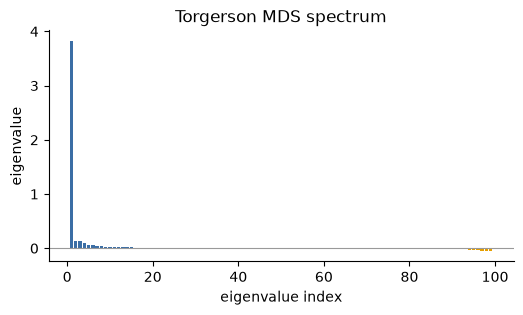

In [6]:
# Classical (Torgerson) MDS: eigendecomposition of the double-centred -D^2/2.
# Deterministic, and its spectrum says how many dimensions the distances need;
# negative eigenvalues measure how far the metric is from being Euclidean.
from scipy.linalg import orthogonal_procrustes
from scipy.spatial.distance import pdist, squareform

n = len(D)
J = np.eye(n) - np.ones((n, n)) / n
B = -0.5 * J @ (D ** 2) @ J
evals, evecs = np.linalg.eigh(B)
order = np.argsort(evals)[::-1]
evals, evecs = evals[order], evecs[:, order]

print("share of the positive spectrum in the first 2 / 3 axes: %.3f / %.3f"
      % (evals[:2].sum() / evals[evals > 0].sum(), evals[:3].sum() / evals[evals > 0].sum()))
print("negative eigenvalue mass |sum neg| / sum pos: %.3f"
      % (-evals[evals < 0].sum() / evals[evals > 0].sum()))

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(np.arange(1, n + 1), evals, color=np.where(evals >= 0, "#3b6ea5", "#E69F00"))
ax.axhline(0, color="0.6", lw=0.8)
ax.set(xlabel="eigenvalue index", ylabel="eigenvalue", title="Torgerson MDS spectrum")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()


In [7]:
# Classical (Torgerson-Gower) 3D MDS: the first three eigenvectors of the double-centred
# -D^2/2 (evals/evecs from the Torgerson cell), scaled by sqrt(eigenvalue). No iterative
# optimisation, so it is deterministic; it fits the double-centred squared distances
# rather than D itself, which is why its Stress-1 against D is higher than that of the
# iterative maps below. It is the reference the later maps are turned onto, which fixes
# the z -> -z reflection that the anchors leave open.
xyz_cmds_3d = evecs[:, :3] * np.sqrt(evals[:3])
D_cmds_3d = squareform(pdist(xyz_cmds_3d))
print("Kruskal stress-1 in 3D: %.3f" % np.sqrt(((D - D_cmds_3d) ** 2).sum() / (D ** 2).sum()))
print("share of the positive spectrum in the first 3 axes: %.3f"
      % (evals[:3].sum() / evals[evals > 0].sum()))

xyz_cmds_3d = anchor_3d(xyz_cmds_3d)
print("max distance change from the anchoring: %.1e"
      % np.abs(squareform(pdist(xyz_cmds_3d)) - D_cmds_3d).max())
coords_cmds_3d = pd.DataFrame(xyz_cmds_3d, index=keep, columns=["x", "y", "z"])
coords_cmds_3d.rename_axis("copula").to_csv("coords_cmds_3d.csv")   # read by the Analysis section below
print(coords_cmds_3d.loc[["(independence)", "(frank25)", "(joe6)", "(joe6)!M01"]])

# its own hover panel, like every 3D map
panel_img_c = widgets.Image(format="png", width=230, height=230)
panel_txt_c = widgets.HTML("<i>hover a point</i>", layout=widgets.Layout(width="240px"))

def hover_handler_c(m):
    def on_hover(trace, points, state):
        if points.point_inds:
            i = m[points.point_inds[0]]
            panel_img_c.value = thumb_png[i]
            panel_txt_c.value = (f"<b style='word-break:break-all'>{keep[i]}</b><br>"
                                 f"Spearman &rho; = {info[i]['rho']:.3f}<br>"
                                 f"Kendall &tau; = {info[i]['tau']:.3f}<br>"
                                 f"<span style='color:#666'>nearest: {keep[nn[i]]}<br>"
                                 f"distance to it: {D[i, nn[i]]:.4f}</span>")
    return on_hover

fig3d_c = go.FigureWidget()
for cat, (color, _, label) in style.items():
    m = np.flatnonzero(cats == cat)
    if len(m) == 0:
        continue
    fig3d_c.add_trace(go.Scatter3d(
        x=xyz_cmds_3d[m, 0], y=xyz_cmds_3d[m, 1], z=xyz_cmds_3d[m, 2], mode="markers",
        name=f"{label} (n={len(m)})",
        marker=dict(size=sizes_3d.get(cat, 5), color=color, symbol=symbols_3d[cat],
                    line=dict(color=color if cat in outline_3d else "white",
                              width=outline_3d.get(cat, 0.5))),
        customdata=[[keep[i], D[i, nn[i]]] for i in m],
        hovertemplate="<b>%{customdata[0]}</b><br>"
                      "(%{x:.4f}, %{y:.4f}, %{z:.4f})<br>"
                      "nearest at %{customdata[1]:.4f}<extra></extra>"))
    fig3d_c.data[-1].on_hover(hover_handler_c(m))
fig3d_c.update_layout(width=760, height=640, margin=dict(l=0, r=0, t=40, b=0),
                      title="Classical (Torgerson) 3D MDS of the constrained Wasserstein distance",
                      scene=dict(aspectmode="data",
                                 xaxis=dict(title="x"), yaxis=dict(title="y"),
                                 zaxis=dict(title="z")),
                      legend=dict(itemsizing="constant", x=0, y=1))

widgets.HBox([fig3d_c, widgets.VBox([panel_img_c, panel_txt_c])])

Kruskal stress-1 in 3D: 0.038
share of the positive spectrum in the first 3 axes: 0.875
max distance change from the anchoring: 1.1e-16
                       x             y             z
(independence)  0.000000  0.000000e+00  0.000000e+00
(frank25)       0.314219 -1.317200e-16  2.354157e-17
(joe6)          0.255324 -4.020409e-02  2.818523e-17
(joe6)!M01      0.255324  4.020409e-02  3.502982e-17


    'data': [{'customdata': [['(khoudraji_gumbel6_0.4)', 0.019542992115020752],
…

In [8]:
# 3D stress MDS (SMACOF), shown as a rotatable plotly scatter (drag to rotate, scroll to zoom,
# click a legend entry to hide that category). Plotly's hover box cannot hold images,
# so hovering a point shows its sample scatter in the panel on the right instead.
mds_3d = MDS(n_components=3, dissimilarity="precomputed", random_state=0, n_init=8,
             max_iter=500, normalized_stress=False)
xyz = mds_3d.fit_transform(D)
print("Kruskal stress-1 in 3D: %.3f" % np.sqrt(mds_3d.stress_ / (0.5 * (D ** 2).sum())))

D_mds_3d = squareform(pdist(xyz))
# fix the z -> -z reflection to match the classical map, then anchor (rigid motions only)
R, _ = orthogonal_procrustes(xyz - xyz.mean(0), xyz_cmds_3d - xyz_cmds_3d.mean(0))
xyz = anchor_3d((xyz - xyz.mean(0)) @ R)
print("max distance change from the anchoring: %.1e"
      % np.abs(squareform(pdist(xyz)) - D_mds_3d).max())
coords_mds_3d = pd.DataFrame(xyz, index=keep, columns=["x", "y", "z"])
print(coords_mds_3d.loc[["(independence)", "(frank25)", "(joe6)", "(joe6)!M01"]])

panel_img = widgets.Image(format="png", width=230, height=230)
panel_txt = widgets.HTML("<i>hover a point</i>", layout=widgets.Layout(width="240px"))

def show_copula(i):
    panel_img.value = thumb_png[i]
    panel_txt.value = (f"<b style='word-break:break-all'>{keep[i]}</b><br>"
                       f"Spearman &rho; = {info[i]['rho']:.3f}<br>"
                       f"Kendall &tau; = {info[i]['tau']:.3f}<br>"
                       f"<span style='color:#666'>nearest: {keep[nn[i]]}<br>"
                       f"distance to it: {D[i, nn[i]]:.4f}</span>")

def hover_handler(m):                   # m: positions in keep of this trace's points
    def on_hover(trace, points, state):
        if points.point_inds:
            show_copula(m[points.point_inds[0]])
    return on_hover

fig3d = go.FigureWidget()
for cat, (color, _, label) in style.items():
    m = np.flatnonzero(cats == cat)
    if len(m) == 0:
        continue
    fig3d.add_trace(go.Scatter3d(
        x=xyz[m, 0], y=xyz[m, 1], z=xyz[m, 2], mode="markers",
        name=f"{label} (n={len(m)})",
        marker=dict(size=sizes_3d.get(cat, 5), color=color, symbol=symbols_3d[cat],
                    line=dict(color=color if cat in outline_3d else "white",
                              width=outline_3d.get(cat, 0.5))),
        customdata=[[keep[i], D[i, nn[i]]] for i in m],
        hovertemplate="<b>%{customdata[0]}</b><br>"
                      "(%{x:.4f}, %{y:.4f}, %{z:.4f})<br>"
                      "nearest at %{customdata[1]:.4f}<extra></extra>"))
    fig3d.data[-1].on_hover(hover_handler(m))
fig3d.update_layout(width=760, height=640, margin=dict(l=0, r=0, t=40, b=0),
                    title="3D MDS of the constrained Wasserstein distance between all copulas",
                    scene=dict(aspectmode="data",      # equal axis scaling, as MDS needs
                               xaxis=dict(title="x"), yaxis=dict(title="y"),
                               zaxis=dict(title="z")),
                    legend=dict(itemsizing="constant", x=0, y=1))

widgets.HBox([fig3d, widgets.VBox([panel_img, panel_txt])])

c:\Users\nicol\bachelor_thesis\bsc_env\Lib\site-packages\sklearn\manifold\_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
c:\Users\nicol\bachelor_thesis\bsc_env\Lib\site-packages\sklearn\manifold\_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(


Kruskal stress-1 in 3D: 0.025
max distance change from the anchoring: 4.4e-16
                       x             y             z
(independence)  0.000000  0.000000e+00  0.000000e+00
(frank25)       0.318535 -5.260377e-19 -7.774186e-19
(joe6)          0.255612 -3.992485e-02 -4.840495e-03
(joe6)!M01      0.255058  4.102661e-02 -4.840495e-03


    'data': [{'customdata': [['(khoudraji_gumbel6_0.4)', 0.019542992115020752],
…

In [9]:
# 3D Sammon mapping: stress weighted by 1/D_ij, so small distances (near neighbours,
# e.g. the isometry variants of one shape) count more than in plain stress MDS.
#   E = (1/c) sum_{i<j} (d_ij - D_ij)^2 / D_ij,   c = sum_{i<j} D_ij
# Minimised with L-BFGS on the analytic gradient, started from the first three
# Torgerson axes and turned onto the classical 3D map, then given the same anchors.
# Shown with the same rotatable plotly view and hover panel.
from scipy.optimize import minimize

W = (D > 0) & ~np.eye(n, dtype=bool)     # pairs at distance 0 carry no Sammon weight
D_w = np.where(W, D, 1.0)
c = 0.5 * D[W].sum()

def sammon_stress_3d(flat):
    Y = flat.reshape(n, 3)
    diff = Y[:, None, :] - Y[None, :, :]
    d = np.sqrt((diff ** 2).sum(-1))
    r = np.where(W, (d - D) / D_w, 0.0)
    E = 0.5 * (r * (d - D)).sum() / c
    G = np.where(W, r / np.where(d > 0, d, 1e-12), 0.0)
    grad = 2.0 / c * (G[:, :, None] * diff).sum(1)
    return E, grad.ravel()

xyz_cmds = evecs[:, :3] * np.sqrt(evals[:3])
res_3d = minimize(sammon_stress_3d, xyz_cmds.ravel(), jac=True, method="L-BFGS-B",
                  options=dict(maxiter=5000, gtol=1e-10))
xyz_sammon = res_3d.x.reshape(n, 3)
D_sammon_3d = squareform(pdist(xyz_sammon))
print(f"{res_3d.message} after {res_3d.nit} iterations")
print("Sammon stress in 3D: %.4f" % res_3d.fun)
print("Kruskal stress-1 in 3D: %.3f" % np.sqrt(((D - D_sammon_3d) ** 2).sum() / (D ** 2).sum()))

R, _ = orthogonal_procrustes(xyz_sammon - xyz_sammon.mean(0), xyz_cmds_3d - xyz_cmds_3d.mean(0))
xyz_sammon = (xyz_sammon - xyz_sammon.mean(0)) @ R

# same anchors as the other 3D maps (rigid motions only, units of D)
xyz_sammon = anchor_3d(xyz_sammon)

print("max distance change from the anchoring: %.1e"
      % np.abs(squareform(pdist(xyz_sammon)) - D_sammon_3d).max())
coords_sammon_3d = pd.DataFrame(xyz_sammon, index=keep, columns=["x", "y", "z"])
print(coords_sammon_3d.loc[["(independence)", "(frank25)", "(joe6)", "(joe6)!M01"]])

# its own hover panel, so hovering here does not update the panels above
panel_img_s = widgets.Image(format="png", width=230, height=230)
panel_txt_s = widgets.HTML("<i>hover a point</i>", layout=widgets.Layout(width="240px"))

def hover_handler_s(m):
    def on_hover(trace, points, state):
        if points.point_inds:
            i = m[points.point_inds[0]]
            panel_img_s.value = thumb_png[i]
            panel_txt_s.value = (f"<b style='word-break:break-all'>{keep[i]}</b><br>"
                                 f"Spearman &rho; = {info[i]['rho']:.3f}<br>"
                                 f"Kendall &tau; = {info[i]['tau']:.3f}<br>"
                                 f"<span style='color:#666'>nearest: {keep[nn[i]]}<br>"
                                 f"distance to it: {D[i, nn[i]]:.4f}</span>")
    return on_hover

fig3d_s = go.FigureWidget()
for cat, (color, _, label) in style.items():
    m = np.flatnonzero(cats == cat)
    if len(m) == 0:
        continue
    fig3d_s.add_trace(go.Scatter3d(
        x=xyz_sammon[m, 0], y=xyz_sammon[m, 1], z=xyz_sammon[m, 2], mode="markers",
        name=f"{label} (n={len(m)})",
        marker=dict(size=sizes_3d.get(cat, 5), color=color, symbol=symbols_3d[cat],
                    line=dict(color=color if cat in outline_3d else "white",
                              width=outline_3d.get(cat, 0.5))),
        customdata=[[keep[i], D[i, nn[i]]] for i in m],
        hovertemplate="<b>%{customdata[0]}</b><br>"
                      "(%{x:.4f}, %{y:.4f}, %{z:.4f})<br>"
                      "nearest at %{customdata[1]:.4f}<extra></extra>"))
    fig3d_s.data[-1].on_hover(hover_handler_s(m))
fig3d_s.update_layout(width=760, height=640, margin=dict(l=0, r=0, t=40, b=0),
                      title="3D Sammon mapping of the constrained Wasserstein distance",
                      scene=dict(aspectmode="data",
                                 xaxis=dict(title="x"), yaxis=dict(title="y"),
                                 zaxis=dict(title="z")),
                      legend=dict(itemsizing="constant", x=0, y=1))

widgets.HBox([fig3d_s, widgets.VBox([panel_img_s, panel_txt_s])])

CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH after 10 iterations
Sammon stress in 3D: 0.0013
Kruskal stress-1 in 3D: 0.026
max distance change from the anchoring: 1.7e-16
                       x             y             z
(independence)  0.000000  0.000000e+00  0.000000e+00
(frank25)       0.318695  9.373661e-16  3.994033e-16
(joe6)          0.255905 -4.141556e-02 -9.046767e-16
(joe6)!M01      0.255905  4.141556e-02 -9.046767e-16


    'data': [{'customdata': [['(khoudraji_gumbel6_0.4)', 0.019542992115020752],
…

17 iterations
non-metric Stress-1 (against the disparities): 0.019
metric Stress-1 (against D, after rescaling): 0.026


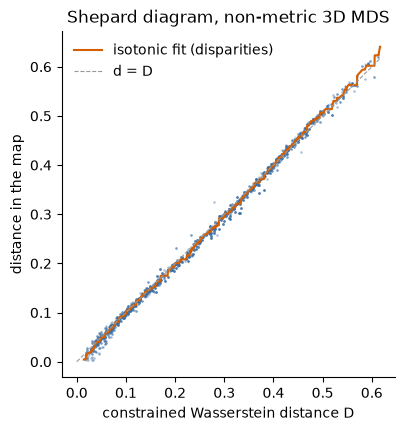

                       x             y             z
(independence)  0.000000  0.000000e+00  0.000000e+00
(frank25)       0.320312 -1.507744e-16  5.943745e-17
(joe6)          0.256817 -3.844811e-02  7.715067e-18
(joe6)!M01      0.256817  3.844811e-02  7.715067e-18


    'data': [{'customdata': [['(khoudraji_gumbel6_0.4)', 0.019542992115020752],
…

In [10]:
# Non-metric (ordinal, Kruskal) 3D MDS: only the rank order of the distances has to be
# kept. The map distances are fitted to "disparities", a monotone (isotonic) regression
# of D, rather than to D itself, so any monotone distortion of D is free.
# Started from the classical-MDS solution (lower stress than 8 random starts here).
# The map's scale is arbitrary, so it is rescaled by least squares onto D before the
# metric Stress-1 is computed; then the same anchors as the other 3D maps are applied.
from sklearn.isotonic import IsotonicRegression

nmds_3d = MDS(n_components=3, metric_mds=False, metric="precomputed", init="classical_mds",
              n_init=1, max_iter=1000, normalized_stress=True)
xyz_nmds = nmds_3d.fit_transform(D)
d_nmds = squareform(pdist(xyz_nmds))
xyz_nmds *= (d_nmds * D).sum() / (d_nmds ** 2).sum()
d_nmds = squareform(pdist(xyz_nmds))
print(f"{nmds_3d.n_iter_} iterations")
print("non-metric Stress-1 (against the disparities): %.3f" % nmds_3d.stress_)
print("metric Stress-1 (against D, after rescaling): %.3f"
      % np.sqrt(((D - d_nmds) ** 2).sum() / (D ** 2).sum()))

# Shepard diagram: map distance against D. The step line is the isotonic fit (the
# disparities); scatter about it is what the non-metric stress measures, and its
# curvature is the monotone distortion of D that the map is allowed.
iu = np.triu_indices(n, k=1)
order_D = np.argsort(D[iu])
disp = IsotonicRegression().fit_transform(D[iu][order_D], d_nmds[iu][order_D])
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(D[iu], d_nmds[iu], s=3, alpha=0.25, color="#3b6ea5", linewidths=0)
ax.plot(D[iu][order_D], disp, color="#D55E00", lw=1.5, label="isotonic fit (disparities)")
ax.plot([0, D.max()], [0, D.max()], color="0.6", lw=0.8, ls="--", label="d = D")
ax.set(xlabel="constrained Wasserstein distance D", ylabel="distance in the map",
       title="Shepard diagram, non-metric 3D MDS", aspect="equal")
ax.legend(frameon=False, loc="upper left")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

# same anchors as the other 3D maps (rigid motions only); the Procrustes step only
# fixes the remaining z -> -z reflection to match the classical map
R, _ = orthogonal_procrustes(xyz_nmds - xyz_nmds.mean(0), xyz_cmds_3d - xyz_cmds_3d.mean(0))
xyz_nmds = anchor_3d((xyz_nmds - xyz_nmds.mean(0)) @ R)

coords_nmds_3d = pd.DataFrame(xyz_nmds, index=keep, columns=["x", "y", "z"])
print(coords_nmds_3d.loc[["(independence)", "(frank25)", "(joe6)", "(joe6)!M01"]])

# its own hover panel, like the Sammon map
panel_img_n = widgets.Image(format="png", width=230, height=230)
panel_txt_n = widgets.HTML("<i>hover a point</i>", layout=widgets.Layout(width="240px"))

def hover_handler_n(m):
    def on_hover(trace, points, state):
        if points.point_inds:
            i = m[points.point_inds[0]]
            panel_img_n.value = thumb_png[i]
            panel_txt_n.value = (f"<b style='word-break:break-all'>{keep[i]}</b><br>"
                                 f"Spearman &rho; = {info[i]['rho']:.3f}<br>"
                                 f"Kendall &tau; = {info[i]['tau']:.3f}<br>"
                                 f"<span style='color:#666'>nearest: {keep[nn[i]]}<br>"
                                 f"distance to it: {D[i, nn[i]]:.4f}</span>")
    return on_hover

fig3d_n = go.FigureWidget()
for cat, (color, _, label) in style.items():
    m = np.flatnonzero(cats == cat)
    if len(m) == 0:
        continue
    fig3d_n.add_trace(go.Scatter3d(
        x=xyz_nmds[m, 0], y=xyz_nmds[m, 1], z=xyz_nmds[m, 2], mode="markers",
        name=f"{label} (n={len(m)})",
        marker=dict(size=sizes_3d.get(cat, 5), color=color, symbol=symbols_3d[cat],
                    line=dict(color=color if cat in outline_3d else "white",
                              width=outline_3d.get(cat, 0.5))),
        customdata=[[keep[i], D[i, nn[i]]] for i in m],
        hovertemplate="<b>%{customdata[0]}</b><br>"
                      "(%{x:.4f}, %{y:.4f}, %{z:.4f})<br>"
                      "nearest at %{customdata[1]:.4f}<extra></extra>"))
    fig3d_n.data[-1].on_hover(hover_handler_n(m))
fig3d_n.update_layout(width=760, height=640, margin=dict(l=0, r=0, t=40, b=0),
                      title="Non-metric 3D MDS of the constrained Wasserstein distance",
                      scene=dict(aspectmode="data",
                                 xaxis=dict(title="x"), yaxis=dict(title="y"),
                                 zaxis=dict(title="z")),
                      legend=dict(itemsizing="constant", x=0, y=1))

widgets.HBox([fig3d_n, widgets.VBox([panel_img_n, panel_txt_n])])

Then, the various metrics belonging to the different types of maps are evaluated for each of them.

In [11]:
# Every 3D map scored on every map's criterion. Each method minimises only one of these,
# but each is a function of the coordinates and D alone, so all four apply to every map:
#   strain          sqrt(sum (B - X X^T)^2 / sum B^2), X centred    (minimised by classical MDS)
#   Stress-1        sqrt(sum (d - D)^2 / sum D^2)                   (SMACOF: raw stress, same minimiser)
#   Sammon stress   sum (d - D)^2 / D  /  sum D                     (Sammon)
#   non-metric S-1  sqrt(sum (d - dhat)^2 / sum dhat^2), dhat the
#                   isotonic regression of d on D                   (non-metric MDS)
# Strain sums over all i, j (B from the Torgerson cell), the others over pairs i < j.
# Strain, Stress-1 and Sammon depend on scale, which is why the non-metric map was
# rescaled onto D; the non-metric stress does not.
# Lower is better in every column; the shaded cell is the best map for that measure.
iu = np.triu_indices(n, k=1)
D_iu = D[iu]
order_D = np.argsort(D_iu, kind="stable")

def stress_table_row(X):
    Xc = X - X.mean(0)
    d = pdist(X)                         # same pair order as D[iu]
    dhat = np.empty_like(d)
    dhat[order_D] = IsotonicRegression().fit_transform(D_iu[order_D], d[order_D])
    pos = D_iu > 0
    return {"strain": np.sqrt(((B - Xc @ Xc.T) ** 2).sum() / (B ** 2).sum()),
            "Stress-1": np.sqrt(((d - D_iu) ** 2).sum() / (D_iu ** 2).sum()),
            "Sammon stress": (((d - D_iu) ** 2)[pos] / D_iu[pos]).sum() / D_iu[pos].sum(),
            "non-metric Stress-1": np.sqrt(((d - dhat) ** 2).sum() / (dhat ** 2).sum())}

maps_3d = {"classical (Torgerson)": xyz_cmds_3d, "stress (SMACOF)": xyz,
           "Sammon": xyz_sammon, "non-metric (Kruskal)": xyz_nmds}
stress_table = pd.DataFrame({name: stress_table_row(X) for name, X in maps_3d.items()}).T
stress_table.index.name = "3D map"

(stress_table.style
     .format("{:.4f}")
     .highlight_min(axis=0, props="background-color: #cfe3f3; font-weight: bold"))

,strain,Stress-1,Sammon stress,non-metric Stress-1
3D map,,,,
classical (Torgerson),0.0498,0.0378,0.0034,0.0274
stress (SMACOF),0.0559,0.0248,0.0014,0.0204
Sammon,0.0603,0.0260,0.0013,0.0207
non-metric (Kruskal),0.0569,0.0259,0.0016,0.0188


A 3d image as well as the projections onto the $xy$-m, $xz$-, and $yz$-plane of the classical MDS map are shown as png files.

c:\Users\nicol\bachelor_thesis\bsc_env\Lib\site-packages\statsmodels\tools\rng_qrng.py:54: FutureWarning: Passing `None` as the seed currently return the NumPy singleton RandomState
(np.random.mtrand._rand). After release 0.13 this will change to using the
default generator provided by NumPy (np.random.default_rng()). If you need
reproducible draws, you should pass a seeded np.random.Generator, e.g.,

import numpy as np
seed = 32839283923801
rng = np.random.default_rng(seed)"

  warnings.warn(_future_warn, FutureWarning)


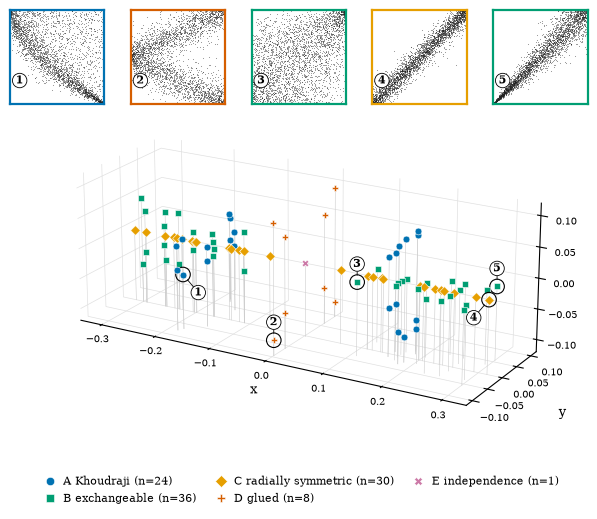

In [12]:
# Static picture of the classical 3D map, for the thesis. matplotlib rather than plotly:
# its PDF is true vector output with embedded fonts (plotly's static export needs
# kaleido plus a Chrome install, and rasterises 3D scenes even inside a PDF).
# One fixed view, set by elev/azim -- find a good one by rotating the plotly map above
# (or an interactive `%matplotlib widget` window) and copy the angles here.
# A single 3D view hides depth, so every point gets a thin drop line to the floor of
# the box: the foot gives its (x, y) position, the line length its z.
# Points are drawn one at a time so that matplotlib depth-sorts each point; one scatter
# per category would be sorted as a block, putting whole categories in front of others.
# Above the map, a row of sample scatter panels for a few chosen copulas: each is numbered,
# framed in its category colour, and the same number marks its (ringed) point in the
# map. The panels are ordered left to right by where their points appear on screen.
from matplotlib.lines import Line2D
from matplotlib.transforms import Bbox
from mpl_toolkits.mplot3d import proj3d

elev, azim = 20, -60
fig_name = "mds_classical_3d"                          # writes .pdf and .png
markers_mpl = {0: "o", 1: "s", 2: "D", 3: "P", 4: "X"}  # the shapes of symbols_3d

# copulas shown as sample panels (edit freely)
panels = ["(glued_frank8@u0_frank8)!T", "(frank25)", "(khoudraji_gumbel6_0.4)!M1",
          "(clayton10)", "(clayton1)!M01"]
# where each number sits relative to its point, in points (default: straight above);
# move one aside when two chosen points are close on screen
label_offset = {"(frank25)": (-11, -13), "(khoudraji_gumbel6_0.4)!M1": (11, -13)}

X = xyz_cmds_3d
lo, hi = X.min(0), X.max(0)
pad = 0.04 * (hi - lo).max()
lo, hi = lo - pad, hi + pad

# a sample from each panel copula; u horizontal, v vertical
n_sample = 3000
np.random.seed(1)
samples = {}
for name in panels:
    s = build(name).sample_u(n_sample)
    samples[name] = s.detach().cpu().numpy() if hasattr(s, "detach") else np.asarray(s)

with plt.rc_context({"font.size": 9, "font.family": "serif", "pdf.fonttype": 42}):
    fig = plt.figure(figsize=(6.3, 5.7))
    ax = fig.add_axes([0, 0.03, 1, 0.80], projection="3d")
    for x, y, z in X:
        ax.plot([x, x], [y, y], [lo[2], z], color="0.8", lw=0.4)
    for (x, y, z), cat in zip(X, cats):
        ax.scatter(x, y, z, s=24, marker=markers_mpl[cat], color=style[cat][0],
                   edgecolors="white", linewidths=0.4, depthshade=False)

    ax.set(xlim=(lo[0], hi[0]), ylim=(lo[1], hi[1]), zlim=(lo[2], hi[2]),
           xlabel="x", ylabel="y")
    ax.set_zlabel("z", labelpad=2)
    ax.set_box_aspect(hi - lo, zoom=1.05)              # equal scaling on all axes, as MDS needs
    ax.view_init(elev=elev, azim=azim)
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.set_pane_color((1, 1, 1, 0))
        axis._axinfo["grid"].update(color="0.88", linewidth=0.5)
    ax.tick_params(labelsize=7, pad=1)

    # where the panel copulas land on screen (projected 2D data coordinates of the map)
    fig.canvas.draw()
    idx = [keep.index(name) for name in panels]
    px, py, _ = proj3d.proj_transform(*X[idx].T, ax.get_proj())
    order = np.argsort(px)                             # panels left to right as on screen

    w, gap = 0.15, (1 - 5 * 0.15) / 6
    for k, j in enumerate(order):
        name, i = panels[j], idx[j]
        color = style[cats[i]][0]
        # ring and number at the point in the map
        ax.scatter(*X[i], s=110, facecolors="none", edgecolors="black", linewidths=0.8,
                   depthshade=False)
        ax.annotate(str(k + 1), xy=(px[j], py[j]), xytext=label_offset.get(name, (0, 13)),
                    textcoords="offset points", ha="center", va="center", fontsize=8,
                    fontweight="bold", zorder=10,
                    bbox=dict(boxstyle="circle,pad=0.15", fc="white", ec="black", lw=0.6),
                    arrowprops=dict(arrowstyle="-", color="black", lw=0.6, shrinkA=0, shrinkB=5))
        # the sample panel
        s = samples[name]
        pa = fig.add_axes([gap + k * (w + gap), 0.72, w, w * 6.3 / 5.7])
        pa.scatter(s[:, 0], s[:, 1], s=0.6, color="#222222", alpha=0.5, linewidths=0,
                   rasterized=False)
        pa.set(xlim=(0, 1), ylim=(0, 1), xticks=[], yticks=[])
        for s in pa.spines.values():
            s.set(color=color, lw=1.6)
        # the panel's number, at the left edge, 3/4 of the way down
        pa.text(0.06, 0.25, str(k + 1), transform=pa.transAxes, ha="left", va="center",
                fontsize=8, fontweight="bold",
                bbox=dict(boxstyle="circle,pad=0.15", fc="white", ec="black", lw=0.6))

    # categories lettered A-E here (0 -> A, 1 -> B, ...) instead of numbered
    handles = [Line2D([], [], ls="", marker=markers_mpl[cat], color=color,
                      markeredgecolor="white", markeredgewidth=0.4, markersize=6,
                      label=f"{'ABCDE'[cat]} {label.split(' ', 1)[1]} (n={(cats == cat).sum()})")
               for cat, (color, _, label) in style.items() if (cats == cat).any()]
    leg = fig.legend(handles=handles, frameon=False, loc="lower center", ncol=3, fontsize=8,
                     bbox_to_anchor=(0.5, 0.0), handletextpad=0.2, columnspacing=1.2)

    # crop to what is drawn: bbox_inches="tight" would keep the 3D axes' empty margins
    # but drop the z label (it misses it in matplotlib 3.11)
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    parts = [a.get_tightbbox(r) for a in (ax.xaxis, ax.yaxis, ax.zaxis)]
    parts += [ax.zaxis.label.get_window_extent(r), leg.get_window_extent(r)]
    parts += [a.get_tightbbox(r) for a in fig.axes if a is not ax]   # the density panels
    corners = np.array(np.meshgrid(*zip(lo, hi))).reshape(3, -1)       # the 8 box corners
    cx, cy, _ = proj3d.proj_transform(*corners, ax.get_proj())
    parts.append(Bbox.null())
    parts[-1].update_from_data_xy(ax.transData.transform(np.c_[cx, cy]))
    crop = Bbox.union(parts).transformed(fig.dpi_scale_trans.inverted()).padded(0.05)
    fig.savefig(fig_name + ".pdf", bbox_inches=crop)
    fig.savefig(fig_name + ".png", bbox_inches=crop, dpi=300)
plt.show()

c:\Users\nicol\bachelor_thesis\bsc_env\Lib\site-packages\statsmodels\tools\rng_qrng.py:54: FutureWarning: Passing `None` as the seed currently return the NumPy singleton RandomState
(np.random.mtrand._rand). After release 0.13 this will change to using the
default generator provided by NumPy (np.random.default_rng()). If you need
reproducible draws, you should pass a seeded np.random.Generator, e.g.,

import numpy as np
seed = 32839283923801
rng = np.random.default_rng(seed)"

  warnings.warn(_future_warn, FutureWarning)


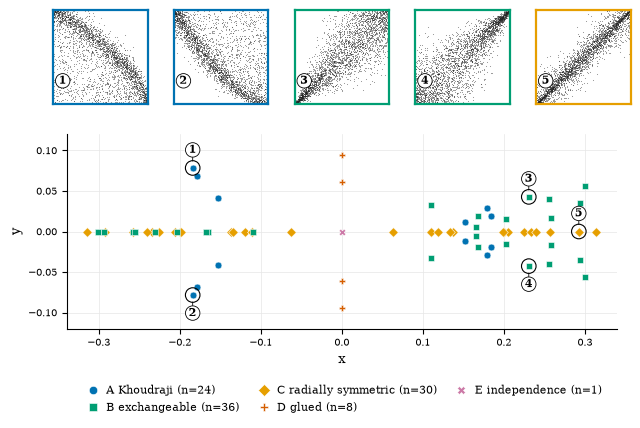

c:\Users\nicol\bachelor_thesis\bsc_env\Lib\site-packages\statsmodels\tools\rng_qrng.py:54: FutureWarning: Passing `None` as the seed currently return the NumPy singleton RandomState
(np.random.mtrand._rand). After release 0.13 this will change to using the
default generator provided by NumPy (np.random.default_rng()). If you need
reproducible draws, you should pass a seeded np.random.Generator, e.g.,

import numpy as np
seed = 32839283923801
rng = np.random.default_rng(seed)"

  warnings.warn(_future_warn, FutureWarning)


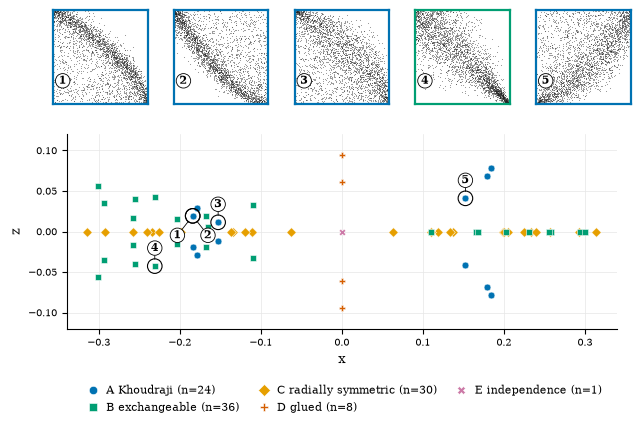

c:\Users\nicol\bachelor_thesis\bsc_env\Lib\site-packages\statsmodels\tools\rng_qrng.py:54: FutureWarning: Passing `None` as the seed currently return the NumPy singleton RandomState
(np.random.mtrand._rand). After release 0.13 this will change to using the
default generator provided by NumPy (np.random.default_rng()). If you need
reproducible draws, you should pass a seeded np.random.Generator, e.g.,

import numpy as np
seed = 32839283923801
rng = np.random.default_rng(seed)"

  warnings.warn(_future_warn, FutureWarning)


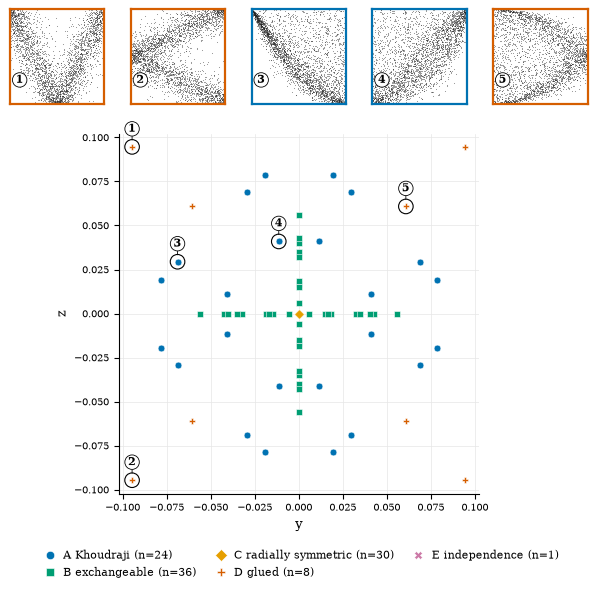

In [13]:
# The classical 3D map projected onto each coordinate plane (xy, xz, yz), one figure
# each, styled like the 3D figure above (markers_mpl, letters A-E in the legend), and
# each with its own row of numbered sample panels for five chosen copulas. Every axis
# is in units of D and equally scaled, so distances along it can be read off directly.
# Points are drawn in order of the dropped coordinate, so where two overlap, the one
# nearer the viewer (larger dropped coordinate) is on top.
def projection_figure(dims, panels, label_offset, fig_name):
    a, b = dims
    P = xyz_cmds_3d[:, [a, b]]
    hidden = xyz_cmds_3d[:, 3 - a - b]
    lo, hi = P.min(0), P.max(0)
    pad = 0.04 * (hi - lo).max()
    lo, hi = lo - pad, hi + pad
    span = hi - lo

    # sizes in inches: map width fixed by the text width, height by equal scaling
    W, map_max_h = 6.3, 3.6
    map_w = W - 0.8
    map_h = map_w * span[1] / span[0]
    if map_h > map_max_h:
        map_h, map_w = map_max_h, map_max_h * span[0] / span[1]
    pw = 0.15 * W                                      # panel side
    below, between, top = 0.95, 0.30, 0.05             # legend + x labels / gap / margin
    H = below + map_h + between + pw + top

    np.random.seed(1)
    samples = {}
    for name in panels:
        s = build(name).sample_u(3000)
        samples[name] = s.detach().cpu().numpy() if hasattr(s, "detach") else np.asarray(s)

    with plt.rc_context({"font.size": 9, "font.family": "serif", "pdf.fonttype": 42}):
        fig = plt.figure(figsize=(W, H))
        ax = fig.add_axes([(W - map_w) / 2 / W, below / H, map_w / W, map_h / H])
        for i in np.argsort(hidden):
            ax.scatter(*P[i], s=24, marker=markers_mpl[cats[i]], color=style[cats[i]][0],
                       edgecolors="white", linewidths=0.4, zorder=2)
        ax.set(xlim=(lo[0], hi[0]), ylim=(lo[1], hi[1]), aspect="equal",
               xlabel="xyz"[a], ylabel="xyz"[b])
        ax.grid(color="0.9", lw=0.5, zorder=0)
        ax.tick_params(labelsize=7)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)

        gap = (1 - 5 * pw / W) / 6
        for k, name in enumerate(panels):              # numbered in list order
            i = keep.index(name)
            ax.scatter(*P[i], s=110, facecolors="none", edgecolors="black", linewidths=0.8,
                       zorder=3)
            ax.annotate(str(k + 1), xy=P[i], xytext=label_offset.get(name, (0, 13)),
                        textcoords="offset points", ha="center", va="center", fontsize=8,
                        fontweight="bold", zorder=4,
                        bbox=dict(boxstyle="circle,pad=0.15", fc="white", ec="black", lw=0.6),
                        arrowprops=dict(arrowstyle="-", color="black", lw=0.6,
                                        shrinkA=0, shrinkB=5))
            s = samples[name]
            pa = fig.add_axes([gap + k * (pw / W + gap), (H - top - pw) / H, pw / W, pw / H])
            pa.scatter(s[:, 0], s[:, 1], s=0.6, color="#222222", alpha=0.5, linewidths=0)
            pa.set(xlim=(0, 1), ylim=(0, 1), xticks=[], yticks=[])
            for sp in pa.spines.values():
                sp.set(color=style[cats[i]][0], lw=1.6)
            # the panel's number, at the left edge, 3/4 of the way down
            pa.text(0.06, 0.25, str(k + 1), transform=pa.transAxes, ha="left", va="center",
                    fontsize=8, fontweight="bold",
                    bbox=dict(boxstyle="circle,pad=0.15", fc="white", ec="black", lw=0.6))

        handles = [Line2D([], [], ls="", marker=markers_mpl[cat], color=color,
                          markeredgecolor="white", markeredgewidth=0.4, markersize=6,
                          label=f"{'ABCDE'[cat]} {label.split(' ', 1)[1]} (n={(cats == cat).sum()})")
                   for cat, (color, _, label) in style.items() if (cats == cat).any()]
        fig.legend(handles=handles, frameon=False, loc="lower center", ncol=3, fontsize=8,
                   bbox_to_anchor=(0.5, 0.0), handletextpad=0.2, columnspacing=1.2)

        fig.savefig(fig_name + ".pdf", bbox_inches="tight", pad_inches=0.05)
        fig.savefig(fig_name + ".png", bbox_inches="tight", pad_inches=0.05, dpi=300)
    plt.show()

# Five copulas per plane, numbered 1-5 in list order, and optionally where a number
# sits relative to its point (in points; default straight above).
# Where a chosen point has a twin differing only in the dropped coordinate (it sits
# exactly on top of it), the one nearer the viewer (dropped coordinate > 0) is taken.
proj_panels = {
    (0, 1): ["(khoudraji_frank25_0.4)!M0", "(khoudraji_frank25_0.4)!T!M0",
             "(clayton4)", "(clayton4)!M01", "(mix_clayton10_clayton10@u0u1)"],
    # 1 and 2 as in xy; here they coincide, since they differ only in y
    (0, 2): ["(khoudraji_frank25_0.4)!M0", "(khoudraji_frank25_0.4)!T!M0",
             "(khoudraji_gaussian0.9_0.4)!M0", "(clayton4)!M0",
             "(khoudraji_gaussian0.9_0.4)!M01"],
    (1, 2): ["(glued_frank8@u0_frank8)", "(glued_frank8@u0_frank8)!T",
             "(khoudraji_gumbel6_0.4)!T!M0", "(khoudraji_gaussian0.9_0.4)!T",
             "(glued_khoudraji_clayton8@u1_u0u1)!T!M0"],
}
proj_label_offset = {(0, 1): {"(clayton4)!M01": (0, -13),
                              "(khoudraji_frank25_0.4)!T!M0": (0, -13)},
                     (0, 2): {"(khoudraji_frank25_0.4)!M0": (-11, -14),
                              "(khoudraji_frank25_0.4)!T!M0": (11, -14)},
                     (1, 2): {}}

for dims, names in proj_panels.items():
    projection_figure(dims, names, proj_label_offset[dims],
                      "mds_classical_" + "xyz"[dims[0]] + "xyz"[dims[1]])

## 3. Analysis

We compare the performance to what the performance would have been using a randomized distance matrix to evaluate if the multidimensional scaling is really significant.

observed Stress-1: 0.0248
permuted Stress-1: mean 0.5080, sd 0.0018, min 0.5019, 5% quantile 0.5050
p = 0.0020  (500 permutations; the smallest attainable is 1/(n_perm+1))


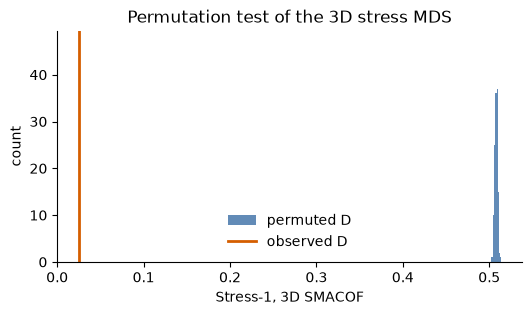

In [14]:
# Permutation test for the 3D stress MDS (Mair, Borg & Rusch 2016, Multivariate Behav.
# Res. 51(6); smacof's permtest()). Null: the same multiset of distances, with the
# assignment of values to copula pairs shuffled -- so the distribution of D, ties
# included, is kept and only the structure (which copula is near which) is destroyed.
# Each shuffled matrix is fitted with exactly the settings of the SMACOF cell above and
# scored with the same Stress-1, so observed and null are comparable. Takes ~0.3 s per
# fit, ~2.5 min for 500. A small p only says the map has structure beyond chance; it is
# a low bar, and says nothing about how faithful the map is (for that see the spectrum
# and the stress table above).
import warnings

n_perm = 500
rng_perm = np.random.default_rng(0)

def smacof_stress1_3d(Dm, seed):
    m = MDS(n_components=3, dissimilarity="precomputed", random_state=seed, n_init=8,
            max_iter=500, normalized_stress=False)
    X = m.fit_transform(Dm)
    return np.sqrt(((Dm - squareform(pdist(X))) ** 2).sum() / (Dm ** 2).sum())

obs_stress = np.sqrt(((D - squareform(pdist(xyz))) ** 2).sum() / (D ** 2).sum())
perm_stress = np.empty(n_perm)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)
    for k in range(n_perm):
        Dp = np.zeros_like(D)
        Dp[iu] = rng_perm.permutation(D[iu])
        Dp += Dp.T
        perm_stress[k] = smacof_stress1_3d(Dp, k)

p_perm = (1 + (perm_stress <= obs_stress).sum()) / (1 + n_perm)
print("observed Stress-1: %.4f" % obs_stress)
print("permuted Stress-1: mean %.4f, sd %.4f, min %.4f, 5%% quantile %.4f"
      % (perm_stress.mean(), perm_stress.std(), perm_stress.min(),
         np.quantile(perm_stress, 0.05)))
print("p = %.4f  (%d permutations; the smallest attainable is 1/(n_perm+1))" % (p_perm, n_perm))

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(perm_stress, bins=30, color="#3b6ea5", alpha=0.8, label="permuted D")
ax.axvline(obs_stress, color="#D55E00", lw=2, label="observed D")
ax.set(xlabel="Stress-1, 3D SMACOF", ylabel="count", xlim=(0, None),
       title="Permutation test of the 3D stress MDS")
ax.legend(frameon=False)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

Corner-mass asymmetries of the campaign copulas are added as two columns of
`correlations_and_corner_densities.csv`:

- `bl-tr` = mass of the bottom-left corner square with side lengths of $\frac{1}{10}$ minus mass of the top-right one
- `tl-br` = mass of the top-left corner minus mass of the bottom-right one

Each mass is exact, read off the joint CDF at the corner square's vertices:

$$\begin{aligned}
P_{\mathrm{BL}} &= C(A,A), & P_{\mathrm{TR}} &= 1 - 2(1-A) + C(1-A,1-A),\\
P_{\mathrm{TL}} &= A - C(A,1-A), & P_{\mathrm{BR}} &= A - C(1-A,A),
\end{aligned}$$


with $A = \frac{1}{10}$.


In [15]:
import numpy as np
import pandas as pd
import torch

from distance_calculation_campaign import unique_pairs as up
from distance_calculation_campaign.copula_families import MirroredCopula, TransposedCopula

A = 0.1                                  # side of each corner square

iso = {"M0": lambda c: MirroredCopula(c, 0), "M1": lambda c: MirroredCopula(c, 1),
       "M01": lambda c: MirroredCopula(c, (0, 1)), "T": TransposedCopula}

def build(name):                        # tags applied left to right, as in run_pair_queue
    head, *tags = name.split("!")
    c = up.unique_shapes[head]
    for t in tags:
        c = iso[t](c)
    return c

res = pd.read_csv("correlations_and_corner_densities.csv", index_col="copula")
print(len(res), "copulas")

101 copulas


In [16]:
def corner_masses(c, a=A):
    pts = torch.tensor([[a, a], [1 - a, 1 - a], [a, 1 - a], [1 - a, a]], dtype=torch.float64)
    with torch.no_grad():
        C_bl, C_tr, C_tl, C_br = c.cdf_u(pts).double().tolist()
    return dict(bl=C_bl, tr=1 - 2 * (1 - a) + C_tr, tl=a - C_tl, br=a - C_br)

m = pd.DataFrame({name: corner_masses(build(name)) for name in res.index}).T
# an (almost) empty corner can come out at ~-5e-11: quadrature noise in the
# bivariate normal CDF, seen for gaussian(0.99)
assert (m.to_numpy() >= -1e-9).all(), "negative corner mass"

res = res.drop(columns=["tr-bl", "br-tl"], errors="ignore")
res["bl-tr"] = m.bl - m.tr
res["tl-br"] = m.tl - m.br
res.to_csv("correlations_and_corner_densities.csv")

pd.set_option("display.max_rows", 120)
res.round(4)

,category,rho,tau,bl-tr,tl-br
copula,,,,,
(khoudraji_gumbel6_0.4),0,0.6693,0.5319,-0.0230,-0.0041
(khoudraji_gumbel6_0.4)!M0,0,-0.6693,-0.5318,0.0041,0.0230
(khoudraji_gumbel6_0.4)!M1,0,-0.6693,-0.5319,-0.0041,-0.0230
(khoudraji_gumbel6_0.4)!M01,0,0.6693,0.5318,0.0230,0.0041
(khoudraji_gumbel6_0.4)!T,0,0.6693,0.5319,-0.0230,0.0041
(khoudraji_gumbel6_0.4)!T!M0,0,-0.6693,-0.5319,-0.0041,0.0230
(khoudraji_gumbel6_0.4)!T!M1,0,-0.6693,-0.5318,0.0041,-0.0230
(khoudraji_gumbel6_0.4)!T!M01,0,0.6693,0.5318,0.0230,-0.0041
(khoudraji_gaussian0.9_0.4),0,0.6177,0.4610,-0.0141,-0.0041


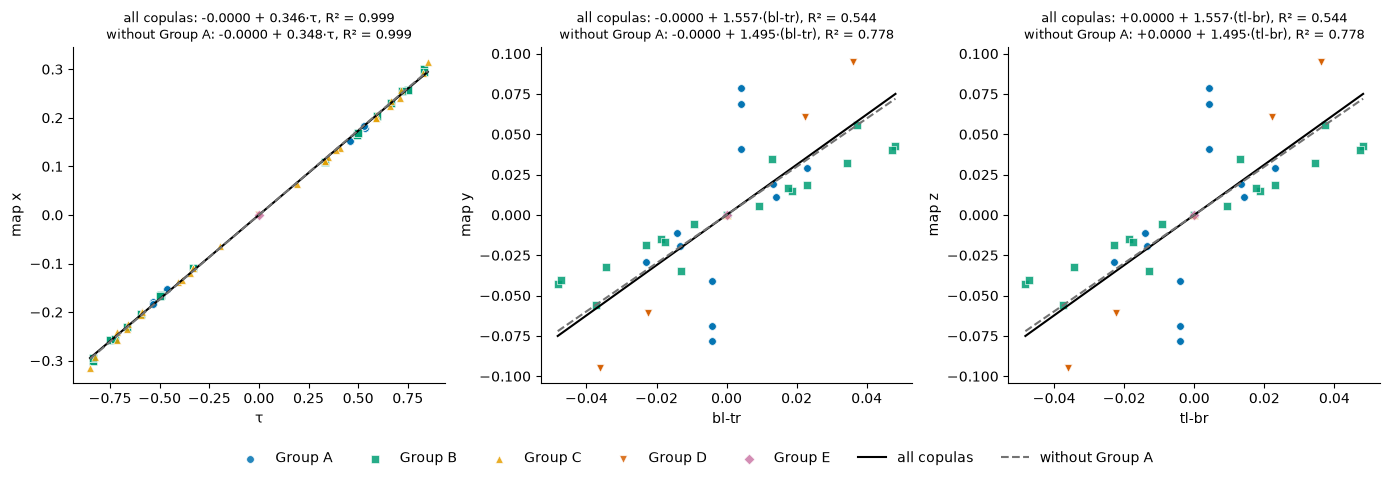

intercept  se_intercept     slope  se_slope  \
x ~ tau   all copulas     -6.552061e-11      0.000588  0.346415  0.001037   
          without Group A -8.697163e-11      0.000688  0.348355  0.001177   
y ~ bl-tr all copulas     -2.933969e-11      0.002444  1.557029  0.144759   
          without Group A -3.718598e-11      0.001686  1.495019  0.093542   
z ~ tl-br all copulas      2.933962e-11      0.002444  1.557029  0.144759   
          without Group A  3.718593e-11      0.001686  1.495019  0.093542   

                                 R2   n  
x ~ tau   all copulas      0.999132  99  
          without Group A  0.999167  75  
y ~ bl-tr all copulas      0.543942  99  
          without Group A  0.777732  75  
z ~ tl-br all copulas      0.543942  99  
          without Group A  0.777732  75

In [17]:
# Each axis of the classical (Torgerson) 3D map above regressed on one
# copula statistic by ordinary least squares with an intercept:
# x ~ tau,  y ~ bl-tr,  z ~ tl-br.
# Each is fitted twice, on all copulas in the map and without the Khoudraji ones
# (category 0). coords_cmds_3d.csv is written by the classical-map cell above (gaussian(0.99)
# is not in it), so rerun that cell first if the map changes.
import matplotlib.pyplot as plt
import statsmodels.api as sm

coords = pd.read_csv("coords_cmds_3d.csv", index_col="copula")
data = coords.join(res, how="inner")
assert len(data) == len(coords), "map copulas missing from correlations_and_corner_densities.csv"

# category colours and markers as in the maps above; categories 0-4 are labelled
# Group A-E in the figure (0 Khoudraji, 1 exchangeable, 2 radially symmetric,
# 3 glued, 4 independence)
style = {0: ("#0072B2", "o", "Group A"),
         1: ("#009E73", "s", "Group B"),
         2: ("#E69F00", "^", "Group C"),
         3: ("#D55E00", "v", "Group D"),
         4: ("#CC79A7", "D", "Group E")}

subsets = {"all copulas":     (data,                      dict(color="black", ls="-")),
           "without Group A": (data[data.category != 0], dict(color="0.45", ls="--"))}

# how each statistic is written on the x axis and in the fitted equation in the titles
axis_label = {"tau": "τ", "bl-tr": "bl-tr", "tl-br": "tl-br"}
title_term = {"tau": "τ", "bl-tr": "(bl-tr)", "tl-br": "(tl-br)"}

fits = {}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))
for ax, (axis, stat) in zip(axes, [("x", "tau"), ("y", "bl-tr"), ("z", "tl-br")]):
    for cat, (color, marker, label) in style.items():
        d = data[data.category == cat]
        ax.scatter(d[stat], d[axis], s=30, marker=marker, color=color, alpha=0.85,
                   edgecolors="white", linewidths=0.5, label=label)
    s = np.linspace(data[stat].min(), data[stat].max(), 2)
    title = []
    for name, (d, line) in subsets.items():
        fit = sm.OLS(d[axis], sm.add_constant(d[stat])).fit()
        b0, b1 = fit.params["const"], fit.params[stat]
        fits[(f"{axis} ~ {stat}", name)] = dict(intercept=b0, se_intercept=fit.bse["const"],
                                                slope=b1, se_slope=fit.bse[stat],
                                                R2=fit.rsquared, n=int(fit.nobs))
        ax.plot(s, b0 + b1 * s, lw=1.5, label=name, **line)
        title.append(f"{name}: {b0:+.4f} + {b1:.3f}·{title_term[stat]}, R² = {fit.rsquared:.3f}")
    ax.set(xlabel=axis_label[stat], ylabel=f"map {axis}")
    ax.set_title("\n".join(title), fontsize=9)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=7, frameon=False)
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

pd.DataFrame(fits).T.astype({"n": int})